# Disaster tweet triage
**AlertMedia take-home · Sr AI/ML Engineer · Ryder Dale Walton**

The notebook follows the exercise:

| Section | Exercise step |
| --- | --- |
| §1 Data | (setup for everything else) |
| §2 Evaluation | Step 1: metrics and the cost of errors |
| §3 Models | Step 2: baseline and one improvement |
| §4 Error analysis | Step 3 |

Steps 4 (LLM evaluation harness) and 5 (two-week plan) are in the README.
Run top to bottom. The fine-tuning cells use Apple Silicon (MPS) or CUDA when available and save
their predictions to `results/`, so later sections can run without retraining.

In [1]:
# §0 Setup
import html, io, re, zipfile
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

HF_REPO = "mhamza-007/binary-class-tweets-dataset"
HF_FILE = "disastrous_tweets.zip"

# How to resolve texts that appear with both labels (see §1):
#   "majority": keep the majority label, drop exact ties    "drop": drop every conflicting text
CONFLICT_POLICY = "majority"

pd.set_option("display.max_colwidth", 110)

## §1 Data

The Hub repo stores the data as a single zip, `disastrous_tweets.zip`, so `datasets.load_dataset`
fails on it (and the Hub's dataset viewer is broken). We download the zip and read the CSV directly.
It is a byte-for-byte copy of Kaggle's *NLP with Disaster Tweets*. Its `test.csv` has no labels,
so all evaluation below uses splits of `train.csv`.

In [2]:
def load_zip() -> zipfile.ZipFile:
    local = DATA_DIR / HF_FILE
    if not local.exists():
        from huggingface_hub import hf_hub_download
        local = Path(hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=DATA_DIR))
    return zipfile.ZipFile(local)

with load_zip() as z:
    print({i.filename: i.file_size for i in z.infolist()})
    raw = pd.read_csv(io.BytesIO(z.read("train.csv")))

print(f"{len(raw):,} labelled tweets · {raw.target.mean():.1%} positive (target = 1)")
raw.head()

/Users/waltonfamilyimac/Developer/disaster-tweets/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'sample_submission.csv': 22746, 'test.csv': 420783, 'train.csv': 987712}
7,613 labelled tweets · 43.0% positive (target = 1)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter i...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


In [3]:
# location is free text and about a third missing, so the models ignore it
raw.isna().sum().to_frame("missing").T

,id,keyword,location,text,target
missing,0,61,2533,0,0


**Every tweet was collected by searching for a disaster keyword.** So the real task is telling a
literal use of a disaster word ("forest fire near La Ronge") from a figurative one ("this mixtape
is fire"), not finding disasters in a general feed. Some keywords nearly decide the label alone,
which is a shortcut that would not survive a broader feed.

In [4]:
kw = raw.groupby("keyword").target.agg(positive_rate="mean", tweets="size").sort_values("positive_rate")
pd.concat([kw.head(5), kw.tail(5)]).round(2)

,positive_rate,tweets
keyword,,
aftershock,0.00,34
body%20bags,0.02,41
ruin,0.03,37
blazing,0.03,34
body%20bag,0.03,33
typhoon,0.97,38
outbreak,0.98,40
debris,1.00,37
wreckage,1.00,39


### Normalize and deduplicate

Retweets and copy-pasted headlines often differ only in their URLs, @handles or HTML entities.
Left in, the same tweet can land in both train and test and inflate every score. We normalize,
collapse each group of duplicates to one row, and resolve texts that carry both labels with
`CONFLICT_POLICY`.

In [5]:
def normalize(text: str) -> str:
    """Lowercase, decode HTML entities, mask URLs and @handles, collapse whitespace."""
    text = html.unescape(text).lower()
    text = re.sub(r"https?://\S+", " httpurl ", text)
    text = re.sub(r"@\w+", " @user ", text)
    return re.sub(r"\s+", " ", text).strip()

df = raw.assign(norm=raw.text.map(normalize))
groups = df.groupby("norm").target.agg(copies="size", positive_rate="mean")
conflicts = groups[(groups.positive_rate > 0) & (groups.positive_rate < 1)]

print(f"{len(df):,} rows → {len(groups):,} unique normalized texts ({len(df) - len(groups):,} duplicate copies)")
print(f"{len(conflicts)} texts appear with both labels ({conflicts.copies.sum()} rows); "
      f"{(conflicts.positive_rate == 0.5).sum()} are exact ties")
conflicts.sort_values("copies", ascending=False).head(5).round(2)

7,613 rows → 6,944 unique normalized texts (669 duplicate copies)
69 texts appear with both labels (245 rows); 32 are exact ties


,copies,positive_rate
norm,,
#hot funtenna: hijacking computers to send data as sound waves [black hat 2015] httpurl #prebreak #best,17,0.29
u.s national park services tonto national forest: stop the annihilation of the salt river wild horse... httpurl via @user,8,0.38
#hot c-130 specially modified to land in a stadium and rescue hostages in iran in 1980 httpurl #prebreak #best,8,0.88
remove the httpurl and linkury browser hijacker httpurl httpurl,7,0.29
spot flood combo 53inch 300w curved cree led work light bar 4x4 offroad fog lamp - full reû_ httpurl httpurl,7,0.14


In [6]:
def dedupe(df: pd.DataFrame, policy: str = CONFLICT_POLICY) -> pd.DataFrame:
    """One row per normalized text; label conflicts resolved by `policy`."""
    g = df.groupby("norm").agg(text=("text", "first"), keyword=("keyword", "first"),
                               copies=("target", "size"), positive_rate=("target", "mean"))
    if policy == "majority":
        g = g[g.positive_rate != 0.5]            # a tie can't be resolved by vote
    elif policy == "drop":
        g = g[g.positive_rate.isin([0, 1])]      # keep unanimous texts only
    else:
        raise ValueError(policy)
    return (g.assign(target=(g.positive_rate > 0.5).astype(int),
                     label_from_vote=~g.positive_rate.isin([0, 1]))
             .drop(columns="positive_rate").reset_index())

data = dedupe(df)
print(f"{CONFLICT_POLICY!r}: {len(data):,} rows kept · {data.target.mean():.1%} positive · "
      f"{data.label_from_vote.sum()} labels set by majority vote")

'majority': 6,912 rows kept · 40.7% positive · 37 labels set by majority vote


### Split

70 / 15 / 15, stratified by label and **grouped by a coarser near-duplicate key** (punctuation,
"RT" prefixes and URL/handle tokens stripped), so near-copies never straddle train and test.
Thresholds and model choices are made on validation. Test is scored once per model, at the end.

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

def near_dup_key(norm_text: str) -> str:
    t = re.sub(r"^rt\b", "", norm_text)
    t = re.sub(r"[^a-z0-9 ]", " ", t)
    t = re.sub(r"\b(httpurl|user)\b", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def grouped_split(data: pd.DataFrame, seed: int = SEED) -> np.ndarray:
    """≈70/15/15 split from 20 stratified, grouped folds: 3 test, 3 validation, 14 train."""
    folds = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=seed)
    fold = np.empty(len(data), dtype=int)
    for k, (_, idx) in enumerate(folds.split(data, data.target, data.group)):
        fold[idx] = k
    return np.select([fold < 3, fold < 6], ["test", "val"], "train")

data["group"] = data.norm.map(near_dup_key)
data["split"] = grouped_split(data)
assert data.groupby("group").split.nunique().max() == 1, "a near-duplicate group crosses splits"

train, val, test = (data[data.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
data.groupby("split").target.agg(rows="size", positive_rate="mean").loc[["train", "val", "test"]].round(3)

,rows,positive_rate
split,,
train,4838,0.407
val,1038,0.408
test,1036,0.406


**Prevalence caveat.** About 41% of these tweets are disasters only because every one was
pre-selected by a disaster keyword. In a live feed the share is far lower, so precision measured
here overstates production precision. §2 shows the correction.

## §2 Evaluation (Step 1)

**The model is a triage layer, not the sender.** Analysts review threats before customers are
alerted, so the classifier decides what analysts *see*:

- A **false positive** costs analyst minutes here (and alert fatigue if it ever reached customers).
- A **false negative** is a threat to people that no analyst ever sees. It can't be recovered later.

So the goal is **maximum recall while the analyst queue stays useful**: precision is a capacity
constraint, not the objective. The README explains each choice.

| Role | Metric |
| --- | --- |
| Headline, threshold-free | Average precision (PR-AUC), with ROC-AUC alongside |
| Operating point | Recall at precision ≥ 0.80, threshold chosen on validation |
| Single-number summary | F2 (recall weighted 2×), plus F1 for comparison with published work |
| Business | Expected cost per 1,000 tweets, a miss = 10, a false alarm = 1 |
| Trust in scores | Brier score and a reliability curve |
| Uncertainty | Bootstrap 95% intervals; paired tests when comparing models (§3) |

In [8]:
# Evaluation settings (my choices; see README, Step 1)
PRECISION_FLOOR = 0.80            # at least 80% of the analyst queue should be real disasters
COST_FN, COST_FP = 10, 1          # a missed disaster costs 10x a false alarm an analyst dismisses
PREVALENCES = [0.01, 0.05, 0.10]  # plausible real-world disaster rates for the precision correction
N_BOOT = 1000

In [9]:
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             fbeta_score, precision_recall_curve, roc_auc_score)

def pick_threshold(y, p, floor=PRECISION_FLOOR) -> float:
    """The threshold with the highest recall whose precision is still >= floor. Use on validation only."""
    prec, rec, thr = precision_recall_curve(y, p)
    ok = prec[:-1] >= floor
    if not ok.any():
        raise ValueError(f"no threshold reaches precision {floor}")
    return float(thr[np.argmax(np.where(ok, rec[:-1], -1))])

def evaluate(y, p, threshold) -> dict:
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "avg_precision": average_precision_score(y, p),
        "roc_auc": roc_auc_score(y, p),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": fbeta_score(y, pred, beta=1, zero_division=0),
        "f2": fbeta_score(y, pred, beta=2, zero_division=0),
        "brier": brier_score_loss(y, p),
        "false_positive_rate": fp / max(fp + tn, 1),
        "cost_per_1k": 1000 * (COST_FN * fn + COST_FP * fp) / len(y),
        "alerts_per_1k": 1000 * (tp + fp) / len(y),
    }

def bootstrap(y, p, threshold, n_boot=N_BOOT, seed=SEED) -> pd.DataFrame:
    """Point estimates with 95% percentile intervals, resampling tweets with replacement."""
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        draws.append(evaluate(y[i], p[i], threshold))
    draws = pd.DataFrame(draws)
    return pd.DataFrame({"value": evaluate(y, p, threshold),
                         "ci_low": draws.quantile(0.025), "ci_high": draws.quantile(0.975)})

**Precision at real-world prevalence.** Holding a model's recall and false-positive rate fixed,
precision at prevalence π is `recall·π / (recall·π + FPR·(1−π))`. Section 3 applies this to each model.

In [10]:
def precision_at_prevalence(recall, fpr, prevalences=PREVALENCES) -> dict:
    return {f"precision at {pi:.0%} prevalence": recall * pi / (recall * pi + fpr * (1 - pi))
            for pi in prevalences}

# Example: 80% recall with a 10% false-positive rate
pd.Series(precision_at_prevalence(0.80, 0.10)).round(3)

precision at 1% prevalence     0.075
precision at 5% prevalence     0.296
precision at 10% prevalence    0.471
dtype: float64

In [11]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

def plot_pr_and_reliability(models: dict, y):
    """models: name -> predicted probabilities for the same tweets."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
    for name, p in models.items():
        prec, rec, _ = precision_recall_curve(y, p)
        ax1.plot(rec, prec, label=f"{name} (AP {average_precision_score(y, p):.3f})")
        observed, predicted = calibration_curve(y, p, n_bins=10, strategy="quantile")
        ax2.plot(predicted, observed, marker="o", ms=4, label=name)
    ax1.axhline(PRECISION_FLOOR, ls="--", c="grey", lw=1)
    ax1.text(0.02, PRECISION_FLOOR + 0.01, f"precision floor {PRECISION_FLOOR:.2f}", color="grey", fontsize=9)
    ax1.set(xlabel="Recall", ylabel="Precision", title="Precision–recall", xlim=(0, 1), ylim=(0.35, 1.01))
    ax2.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
    ax2.set(xlabel="Predicted probability", ylabel="Observed disaster rate", title="Reliability")
    ax1.legend(loc="lower left")
    ax2.legend(loc="upper left")
    fig.tight_layout()
    return fig

Matplotlib is building the font cache; this may take a moment.


**Sanity check.** Before training anything, score a trivial model on validation: each tweet gets
its keyword's disaster rate in train. This tests the harness and measures how strong the keyword
shortcut is.

In [12]:
kw_rate = train.groupby(train.keyword.fillna("none")).target.mean()
p_keyword = val.keyword.fillna("none").map(kw_rate).fillna(train.target.mean())
print(f"keyword-only, validation: average precision {average_precision_score(val.target, p_keyword):.3f}, "
      f"ROC-AUC {roc_auc_score(val.target, p_keyword):.3f}  "
      f"(chance: {val.target.mean():.3f} and 0.500)")

keyword-only, validation: average precision 0.758, ROC-AUC 0.797  (chance: 0.408 and 0.500)


In [13]:
RESULTS, TEST_PROBS = {}, {}

def score_model(name, p_val, p_test) -> pd.DataFrame:
    """Pick the operating threshold on validation, then score test once, with bootstrap intervals."""
    t = pick_threshold(val.target, p_val)
    RESULTS[name] = bootstrap(test.target, p_test, t)
    RESULTS[name].attrs["threshold"] = t
    TEST_PROBS[name] = np.asarray(p_test)
    print(f"{name}: threshold {t:.3f} (chosen on validation for precision ≥ {PRECISION_FLOOR})")
    return RESULTS[name].round(3)

## §3 Models (Step 2)

- **Baseline:** TF-IDF on word 1–2-grams plus character 2–5-grams, into logistic regression.
  Character n-grams pick up hashtags, misspellings and word fragments, which matter in tweets.
- **Improvement:** fine-tune a small transformer (DistilBERT). Published results on this data put
  a fine-tuned transformer about 4–5 F1 points above TF-IDF, while frozen sentence embeddings with
  logistic regression land within noise of TF-IDF. So fine-tuning is the one improvement most
  likely to be real, and the comparison below tests whether it is.

### §3a Baseline: TF-IDF + logistic regression

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union

def make_baseline(C: float = 1.0):
    features = make_union(
        TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
    )
    return make_pipeline(features, LogisticRegression(C=C, max_iter=2000))

# Regularization strength chosen on validation by average precision
val_ap = {C: average_precision_score(val.target,
                                     make_baseline(C).fit(train.norm, train.target).predict_proba(val.norm)[:, 1])
          for C in [0.25, 0.5, 1, 2, 4, 8]}
best_C = max(val_ap, key=val_ap.get)
print("validation average precision by C:", {c: round(v, 3) for c, v in val_ap.items()}, "→ C =", best_C)

validation average precision by C: {0.25: 0.847, 0.5: 0.86, 1: 0.864, 2: 0.864, 4: 0.86, 8: 0.856} → C = 2


In [15]:
baseline = make_baseline(best_C).fit(train.norm, train.target)
p_val_base = baseline.predict_proba(val.norm)[:, 1]
p_test_base = baseline.predict_proba(test.norm)[:, 1]
score_model("TF-IDF + LR", p_val_base, p_test_base)

TF-IDF + LR: threshold 0.470 (chosen on validation for precision ≥ 0.8)


,value,ci_low,ci_high
avg_precision,0.853,0.823,0.879
roc_auc,0.864,0.839,0.886
precision,0.786,0.744,0.824
recall,0.722,0.678,0.763
f1,0.752,0.718,0.783
f2,0.734,0.697,0.771
brier,0.140,0.129,0.152
false_positive_rate,0.135,0.108,0.162
cost_per_1k,1209.459,1025.024,1401.569
alerts_per_1k,373.552,343.629,403.475


In [16]:
# What the baseline learned: the strongest word features in each direction
words = baseline[0].transformer_list[0][1].get_feature_names_out()
weights = pd.Series(baseline[-1].coef_[0][:len(words)], index=words).sort_values()
pd.DataFrame({"→ not a disaster": weights.index[:12], "→ disaster": weights.index[::-1][:12]})

,→ not a disaster,→ disaster
0,you,in
1,new,fires
2,my,storm
3,let,floods
4,all,massacre
5,the new,hiroshima
6,full,were
7,in an,near
8,drowning in,earthquake
9,love,drought


### §3b Improvement: fine-tuned DistilBERT

Trains on Apple Silicon (MPS), CUDA or CPU, in a few minutes on a recent Mac. It keeps the epoch
with the best validation average precision, then saves validation and test predictions to
`results/finetune_predictions.csv`, so the notebook re-runs without retraining (set
`FORCE_RETRAIN = True` to train again). A warning that some classifier weights are newly
initialized is expected: that's the head being trained.

In [17]:
MODEL_NAME = "distilbert-base-uncased"   # alternative: "cardiffnlp/twitter-roberta-base" (tweet-pretrained, slower)
EPOCHS, BATCH_SIZE, LEARNING_RATE, MAX_LEN = 3, 32, 3e-5, 64
FT_PREDS = RESULTS_DIR / "finetune_predictions.csv"
FORCE_RETRAIN = False

In [18]:
def finetune():
    import json, platform, time
    import torch
    from torch.utils.data import DataLoader, TensorDataset
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

    def loader(frame, shuffle):
        enc = tokenizer(list(frame.norm), truncation=True, max_length=MAX_LEN,
                        padding="max_length", return_tensors="pt")
        ds = TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(frame.target.values))
        return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                          generator=torch.Generator().manual_seed(SEED))

    @torch.no_grad()
    def margins(dl):
        """Logit(disaster) − logit(not disaster) for every tweet: the model's raw score."""
        model.eval()
        out = [model(input_ids=x.to(device), attention_mask=m.to(device)).logits.float().cpu() for x, m, _ in dl]
        logits = torch.cat(out)
        return (logits[:, 1] - logits[:, 0]).numpy()

    train_dl, val_dl, test_dl = loader(train, True), loader(val, False), loader(test, False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total_steps = EPOCHS * len(train_dl)
    warmup = int(0.1 * total_steps)   # linear warm-up for 10% of steps, then linear decay to 0
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: min((step + 1) / warmup, max(0.0, (total_steps - step) / (total_steps - warmup))))

    best = {"ap": -1.0}
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for x, m, y in train_dl:
            loss = model(input_ids=x.to(device), attention_mask=m.to(device), labels=y.to(device)).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
        ap = average_precision_score(val.target, margins(val_dl))
        print(f"epoch {epoch}: validation average precision {ap:.4f} ({time.time() - start:.0f}s on {device})")
        if ap > best["ap"]:
            best = {"ap": ap, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}

    model.load_state_dict(best["state"])
    preds = pd.concat([pd.DataFrame({"split": "val", "norm": val.norm, "margin": margins(val_dl)}),
                       pd.DataFrame({"split": "test", "norm": test.norm, "margin": margins(test_dl)})])
    preds.to_csv(FT_PREDS, index=False)
    (RESULTS_DIR / "finetune_run.json").write_text(json.dumps({
        "model": MODEL_NAME, "device": device, "best_epoch": best["epoch"], "epochs": EPOCHS,
        "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "max_len": MAX_LEN, "transformers": __import__("transformers").__version__,
        "train_seconds": round(time.time() - start), "torch": torch.__version__,
        "machine": platform.platform()}, indent=2))
    print(f"kept epoch {best['epoch']}; predictions saved to {FT_PREDS.relative_to(ROOT)}")

if FORCE_RETRAIN or not FT_PREDS.exists():
    finetune()

W1109 21:49:32.043000 46888 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|                                                                         | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 20145.55it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: validation average precision 0.8848 (50s on mps)


epoch 2: validation average precision 0.8898 (100s on mps)


epoch 3: validation average precision 0.8893 (149s on mps)


kept epoch 2; predictions saved to results/finetune_predictions.csv


**Calibration.** Fine-tuned networks are often overconfident, so a single temperature T is fit on
validation (Guo et al., 2017): probability = sigmoid(margin / T). This leaves the ranking, and so
average precision and ROC-AUC, unchanged, but makes the probabilities mean what they say, which
the threshold, the cost metric and any cascade (Step 4) rely on.

In [19]:
from scipy.optimize import minimize_scalar

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def fit_temperature(margin, y) -> float:
    """Temperature that minimizes log-loss on the given (validation) data."""
    def nll(T):
        p = np.clip(sigmoid(margin / T), 1e-12, 1 - 1e-12)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x

ft = pd.read_csv(FT_PREDS, keep_default_na=False)
ft_val, ft_test = ft[ft.split == "val"], ft[ft.split == "test"]
assert (ft_val.norm.values == val.norm.values).all() and (ft_test.norm.values == test.norm.values).all(), \
    "saved predictions don't match the current split: set FORCE_RETRAIN = True"

T = fit_temperature(ft_val.margin.values, val.target.values)
p_val_ft, p_test_ft = sigmoid(ft_val.margin.values / T), sigmoid(ft_test.margin.values / T)
print(f"temperature {T:.2f} (above 1 means the raw model was overconfident); validation Brier "
      f"{brier_score_loss(val.target, sigmoid(ft_val.margin.values)):.3f} raw → {brier_score_loss(val.target, p_val_ft):.3f} scaled")

FT_NAME = "Fine-tuned " + MODEL_NAME.split("/")[-1]
score_model(FT_NAME, p_val_ft, p_test_ft)

temperature 1.10 (above 1 means the raw model was overconfident); validation Brier 0.116 raw → 0.116 scaled


Fine-tuned distilbert-base-uncased: threshold 0.389 (chosen on validation for precision ≥ 0.8)


,value,ci_low,ci_high
avg_precision,0.882,0.857,0.904
roc_auc,0.888,0.866,0.907
precision,0.816,0.780,0.851
recall,0.781,0.740,0.818
f1,0.799,0.769,0.825
f2,0.788,0.752,0.820
brier,0.120,0.107,0.134
false_positive_rate,0.120,0.096,0.144
cost_per_1k,959.459,805.019,1128.378
alerts_per_1k,388.996,359.073,417.954


### §3c Comparison (test set)

Each model's threshold was chosen on validation for precision ≥ 0.80, then applied once to test.

In [20]:
names = list(RESULTS)
shown = ["avg_precision", "roc_auc", "precision", "recall", "f2", "f1", "brier", "cost_per_1k", "alerts_per_1k"]
fmt = lambda t: t.loc[shown].apply(lambda r: f"{r.value:.3f}  [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
pd.DataFrame({n: fmt(RESULTS[n]) for n in names}).rename_axis("test, value [95% CI]")

,TF-IDF + LR,Fine-tuned distilbert-base-uncased
"test, value [95% CI]",,
avg_precision,"0.853 [0.823, 0.879]","0.882 [0.857, 0.904]"
roc_auc,"0.864 [0.839, 0.886]","0.888 [0.866, 0.907]"
precision,"0.786 [0.744, 0.824]","0.816 [0.780, 0.851]"
recall,"0.722 [0.678, 0.763]","0.781 [0.740, 0.818]"
f2,"0.734 [0.697, 0.771]","0.788 [0.752, 0.820]"
f1,"0.752 [0.718, 0.783]","0.799 [0.769, 0.825]"
brier,"0.140 [0.129, 0.152]","0.120 [0.107, 0.134]"
cost_per_1k,"1209.459 [1025.024, 1401.569]","959.459 [805.019, 1128.378]"
alerts_per_1k,"373.552 [343.629, 403.475]","388.996 [359.073, 417.954]"


In [21]:
from scipy.stats import binomtest

def compare(a: str, b: str, n_boot: int = N_BOOT, seed: int = SEED) -> pd.DataFrame:
    """Paired bootstrap of the difference (b − a), plus McNemar's exact test, at each model's own threshold."""
    y, pa, pb = test.target.values, TEST_PROBS[a], TEST_PROBS[b]
    ta, tb = RESULTS[a].attrs["threshold"], RESULTS[b].attrs["threshold"]
    keys = ["avg_precision", "recall", "precision", "f2", "cost_per_1k"]
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        ea, eb = evaluate(y[i], pa[i], ta), evaluate(y[i], pb[i], tb)
        draws.append({k: eb[k] - ea[k] for k in keys})
    draws = pd.DataFrame(draws)
    ea, eb = evaluate(y, pa, ta), evaluate(y, pb, tb)
    right_a, right_b = (pa >= ta) == y, (pb >= tb) == y
    only_a, only_b = int((right_a & ~right_b).sum()), int((~right_a & right_b).sum())
    print(f"McNemar: only {b} right on {only_b} tweets, only {a} right on {only_a}; "
          f"exact p = {binomtest(only_b, only_a + only_b, 0.5).pvalue:.4f}")
    return pd.DataFrame({"difference": {k: eb[k] - ea[k] for k in keys},
                         "ci_low": draws.quantile(0.025), "ci_high": draws.quantile(0.975)}).round(3)

compare(*names)

McNemar: only Fine-tuned distilbert-base-uncased right on 85 tweets, only TF-IDF + LR right on 51; exact p = 0.0045


,difference,ci_low,ci_high
avg_precision,0.029,0.013,0.044
recall,0.059,0.026,0.092
precision,0.031,-0.006,0.066
f2,0.054,0.026,0.083
cost_per_1k,-250.000,-383.205,-114.865


In [22]:
# Precision each model would have at real-world prevalence, holding its test recall and FPR fixed
pd.DataFrame({n: precision_at_prevalence(RESULTS[n].loc["recall", "value"],
                                         RESULTS[n].loc["false_positive_rate", "value"]) for n in names}).round(3)

,TF-IDF + LR,Fine-tuned distilbert-base-uncased
precision at 1% prevalence,0.051,0.062
precision at 5% prevalence,0.220,0.255
precision at 10% prevalence,0.373,0.419


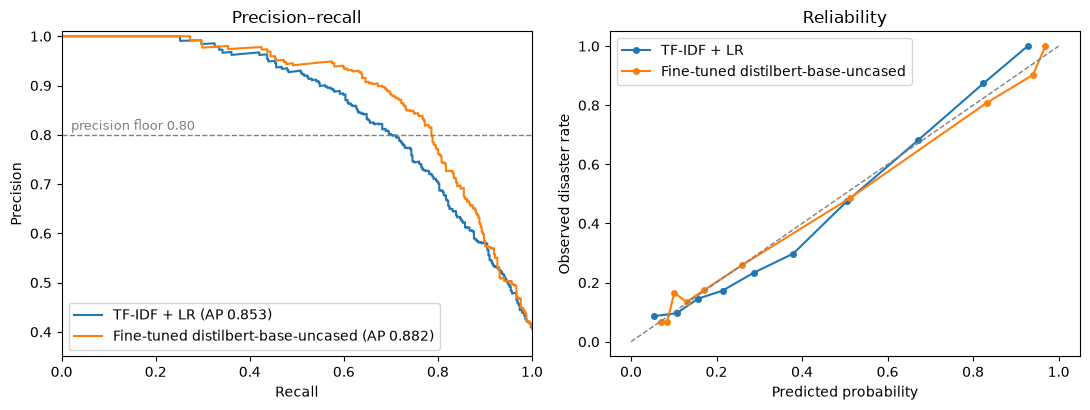

In [23]:
import json
fig = plot_pr_and_reliability(TEST_PROBS, test.target)
fig.savefig(RESULTS_DIR / "pr_reliability.png", dpi=120, bbox_inches="tight")
metrics = {n: {"threshold": RESULTS[n].attrs["threshold"], **RESULTS[n].round(4).to_dict(orient="index")}
           for n in names}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
plt.show()